In [ ]:
from google.colab import files

uploaded = files.upload()

Saving customer_reviewers.tsv to customer_reviewers.tsv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))

df = pd.read_csv(filename, sep='\t')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))


Dataset loaded successfully!
Dataset shape: (3150, 5)


,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1
5,5,31-Jul-18,Heather Gray Fabric,I received the echo as a gift. I needed anothe...,1
6,3,31-Jul-18,Sandstone Fabric,"Without having a cellphone, I cannot use many ...",1
7,5,31-Jul-18,Charcoal Fabric,I think this is the 5th one I've purchased. I'...,1
8,5,30-Jul-18,Heather Gray Fabric,looks great,1
9,5,30-Jul-18,Heather Gray Fabric,Love it! I’ve listened to songs I haven’t hear...,1


In [ ]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64

Total missing values:
1


In [ ]:
# Count positive and negative reviews
print("Sentiment Distribution:")
print(df['feedback'].value_counts())

print("\nSentiment Percentages:")
print(df['feedback'].value_counts(normalize=True) * 100)


Sentiment Distribution:
feedback
1    2893
0     257
Name: count, dtype: int64

Sentiment Percentages:
feedback
1    91.84127
0     8.15873
Name: proportion, dtype: float64


In [ ]:
# Remove missing values
df = df.dropna().reset_index(drop=True)

# Verify missing values have been removed
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)

Missing values after cleaning:
rating              0
date                0
variation           0
verified_reviews    0
feedback            0
dtype: int64

Dataset shape: (3149, 5)


In [ ]:
# Import libraries for text cleaning
import nltk
import re
import html
from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

# Preserve important sentiment words
stop_words -= {'no', 'not', 'nor'}

# Function to remove stop words
def remove_stopwords(data):
    data = data.copy()

    def clean_review(review):
        review = html.unescape(str(review)).lower()
        review = review.replace("’", "'")
        review = re.sub(r"n't\b", " not", review)
        review = re.sub(r'[^a-z\s]', ' ', review)

        words = review.split()

        words = [
            word for word in words
            if word not in stop_words
        ]

        return ' '.join(words)

    data['cleaned_reviews'] = (
        data['verified_reviews'].apply(clean_review)
    )

    return data

df = remove_stopwords(df)

print("Reviews cleaned successfully!")

display(df[['verified_reviews', 'cleaned_reviews']].head(10))

Reviews cleaned successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,verified_reviews,cleaned_reviews
0,Love my Echo!,love echo
1,Loved it!,loved
2,"Sometimes while playing a game, you can answer...",sometimes playing game answer question correct...
3,I have had a lot of fun with this thing. My 4 ...,lot fun thing yr old learns dinosaurs control ...
4,Music,music
5,I received the echo as a gift. I needed anothe...,received echo gift needed another bluetooth so...
6,"Without having a cellphone, I cannot use many ...",without cellphone cannot use many features ipa...
7,I think this is the 5th one I've purchased. I'...,think th one purchased working getting one eve...
8,looks great,looks great
9,Love it! I’ve listened to songs I haven’t hear...,love listened songs not heard since childhood ...


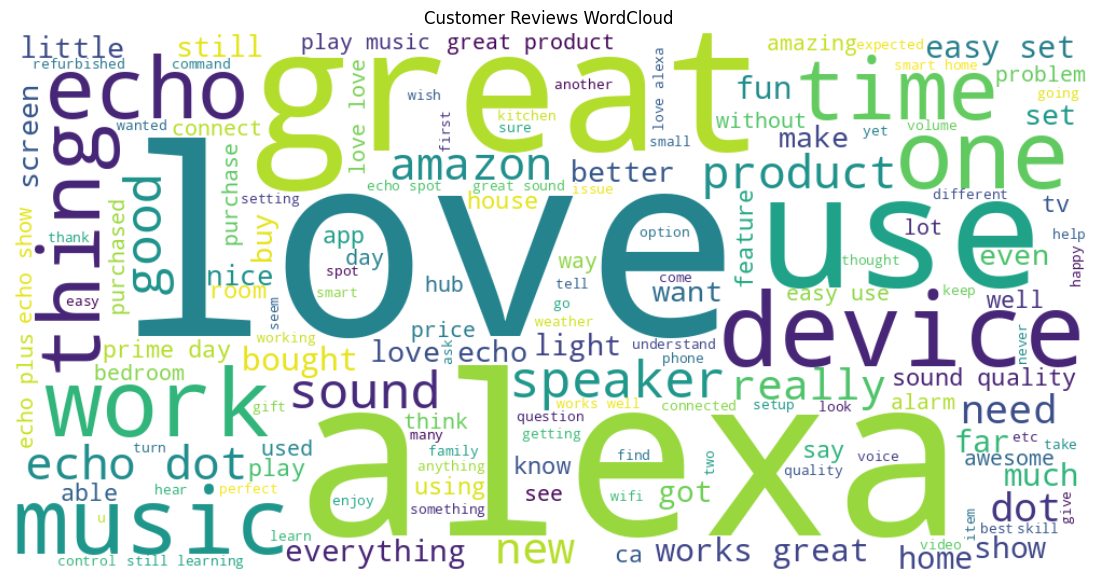

In [ ]:
# Generate WordCloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

all_reviews = ' '.join(df['cleaned_reviews'])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=150
).generate(all_reviews)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Customer Reviews WordCloud')
plt.show()


In [ ]:
# Encode sentiment labels
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

Y = label_encoder.fit_transform(df['feedback'])

print("Original labels:", df['feedback'].unique())
print("Encoded classes:", label_encoder.classes_)
print("First 10 encoded labels:", Y[:10])
print("Label shape:", Y.shape)

Original labels: [1 0]
Encoded classes: [0 1]
First 10 encoded labels: [1 1 1 1 1 1 1 1 1 1]
Label shape: (3149,)


In [ ]:
# Convert reviews into numerical sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 500

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token='<OOV>'
)

tokenizer.fit_on_texts(df['cleaned_reviews'])

sequences = tokenizer.texts_to_sequences(
    df['cleaned_reviews']
)

X = pad_sequences(sequences)

print("Tokenization completed successfully!")
print("Input shape:", X.shape)

print("\nOriginal cleaned review:")
print(df['cleaned_reviews'].iloc[0])

print("\nNumerical sequence:")
print(sequences[0])

print("\nPadded sequence:")
print(X[0])

Tokenization completed successfully!
Input shape: (3149, 257)

Original cleaned review:
love echo

Numerical sequence:
[3, 4]

Padded sequence:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 3 4]


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    LSTM,
    Dense
)

# Build the neural network
model = Sequential()

model.add(Input(shape=(X.shape[1],)))
model.add(Embedding(500, 120))
model.add(SpatialDropout1D(0.4))

model.add(LSTM(
    176,
    dropout=0.2,
    recurrent_dropout=0.2
))

model.add(Dense(2, activation='softmax'))

# Compile the model
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Display model configuration
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 257, 120)       │        60,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 257, 120)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 176)            │       209,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,442 (1.03 MB)

 Trainable params: 269,442 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.utils import to_categorical

# Convert labels into categorical format
Y_categorical = to_categorical(Y, num_classes=2)

print("First 10 categorical labels:")
print(Y_categorical[:10])

print("\nCategorical shape:", Y_categorical.shape)

First 10 categorical labels:
[[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]

Categorical shape: (3149, 2)


In [ ]:
from sklearn.model_selection import train_test_split

# Split reviews and labels
train_reviews, test_reviews, Y_train, Y_test = train_test_split(
    df['cleaned_reviews'],
    Y_categorical,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

# Fit tokenizer using training reviews only
tokenizer = Tokenizer(num_words=500, oov_token='<OOV>')
tokenizer.fit_on_texts(train_reviews)

# Convert reviews into padded numerical arrays
X_train = pad_sequences(
    tokenizer.texts_to_sequences(train_reviews),
    maxlen=X.shape[1]
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(test_reviews),
    maxlen=X.shape[1]
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)

X_train shape: (2519, 257)
X_test shape: (630, 257)
Y_train shape: (2519, 2)
Y_test shape: (630, 2)


In [ ]:
# Train the LSTM model
history = model.fit(
    X_train,
    Y_train,
    epochs=5,
    batch_size=32,
    verbose='auto'
)

Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - accuracy: 0.9150 - loss: 0.2928
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.9226 - loss: 0.2238
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 77s 978ms/step - accuracy: 0.9333 - loss: 0.1701
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 82s 977ms/step - accuracy: 0.9516 - loss: 0.1358
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.9508 - loss: 0.1279


In [ ]:
from google.colab import drive
import numpy as np

drive.mount('/content/drive')

model.save('/content/drive/MyDrive/sentiment_model.keras')

np.savez(
    '/content/drive/MyDrive/sentiment_test_data.npz',
    X_test=X_test,
    Y_test=Y_test
)

print("Model and testing data saved successfully!")

Mounted at /content/drive
Model and testing data saved successfully!


In [15]:
print("Model available:", 'model' in globals())
print("Testing data available:", 'X_test' in globals())

Model available: True
Testing data available: True


In [16]:
import numpy as np

# Predict sentiment using testing data
Y_pred = model.predict(X_test)

# Convert predictions into class labels
Y_pred_classes = np.argmax(Y_pred, axis=1)

# Convert actual labels into class labels
Y_test_classes = np.argmax(Y_test, axis=1)

print("Predictions completed successfully!")

print("\nFirst 10 predicted labels:")
print(Y_pred_classes[:10])

print("\nFirst 10 actual labels:")
print(Y_test_classes[:10])

print("\nTotal predictions:", len(Y_pred_classes))



20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 229ms/step
Predictions completed successfully!

First 10 predicted labels:
[1 1 1 1 1 1 1 1 1 1]

First 10 actual labels:
[1 1 1 1 1 1 1 1 1 1]

Total predictions: 630


In [18]:
from sklearn.metrics import classification_report

print("Sentiment Analysis Classification Report:\n")

print(classification_report(
    Y_test_classes,
    Y_pred_classes,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    digits=4,
    zero_division=0
))

Sentiment Analysis Classification Report:

              precision    recall  f1-score   support

    Negative     0.5938    0.3725    0.4578        51
    Positive     0.9465    0.9775    0.9618       579

    accuracy                         0.9286       630
   macro avg     0.7701    0.6750    0.7098       630
weighted avg     0.9179    0.9286    0.9210       630



In [20]:
from importlib.metadata import version

packages = [
    'pandas',
    'numpy',
    'matplotlib',
    'nltk',
    'wordcloud',
    'scikit-learn',
    'tensorflow',
    'keras'
]

with open('requirements.txt', 'w') as file:
    for package in packages:
        file.write(f"{package}=={version(package)}\n")

print("Requirements file created successfully!")

with open('requirements.txt', 'r') as file:
    print(file.read())

Requirements file created successfully!
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
nltk==3.9.1
wordcloud==1.9.6
scikit-learn==1.6.1
tensorflow==2.21.0
keras==3.13.2



In [21]:
from google.colab import files

files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>